# Polyspectrum Tutorial: N-point statistics

General N-point polyspectrum estimator implemented in `tools21cm.Polyspectrum` and `tools21cm.Bispectrum`,
following **Watkinson et al. 2017** ([arXiv:1705.06284](https://arxiv.org/abs/1705.06284)).

The estimator evaluates

$$P_n(\mathbf{k}_1,\ldots,\mathbf{k}_n) = \frac{V^{n-1}}{N^n}\frac{\sum_x d_1 \cdots d_n}{\sum_x s_1 \cdots s_n}$$

where $d_i = \mathrm{IFFT}[\hat{\delta}\,W_i]$, $s_i = \mathrm{IFFT}[W_i]$, and $W_i$ is a spherical
shell window centred at $k_i$.  Special cases: $n=2$ → power spectrum; $n=3$ → bispectrum.

Analytical solutions for the **bubble field** (Poisson-distributed identical spheres) follow
[Bharadwaj & Pandey 2005](https://academic.oup.com/mnras/article/358/3/968/1028528) and are
overlaid on every plot.

**Contents**
1. Test fields (Gaussian random field + bubble model)
2. Power spectrum — Polyspectrum $(n=2)$ vs `power_spectrum_1d`
3. Equilateral bispectrum — tools21cm vs Pylians
4. Isosceles bispectrum — tools21cm vs Pylians
5. Reduced bispectrum $Q_{\rm eq}$


In [1]:
import numpy as np
from scipy.special import spherical_jn
import matplotlib.pyplot as plt
import tools21cm as t2c
from tools21cm import power_spectrum_1d
from tools21cm.polyspectrum import Polyspectrum
from tools21cm.bispectrum import Bispectrum, BispectrumPylians

try:
    import Pk_library as PKL
    _pylians = True
    print('Pylians3 available — comparison cells will run')
except ImportError:
    _pylians = False
    print('Pylians3 not installed — Pylians comparison cells will be skipped')

print(f'tools21cm {t2c.__version__}')

Pylians3 available — comparison cells will run
tools21cm 2.4.1


## 1. Test fields

Two physically motivated fields on a $64^3$ grid ($L=200\,\mathrm{Mpc}$):

* **GRF** — Gaussian random field with $P(k)\propto k^{-3}$ (representative 21-cm spectrum).
  All polyspectra $n\geq 3$ are statistically consistent with zero.
* **Bubble field** — Poisson-distributed spherical ionised bubbles ($R=8\,\mathrm{Mpc}$,
  80 bubbles).  Has a known analytic power- and bi-spectrum (Bharadwaj & Pandey 2005).


In [2]:
N       = 64
box_Mpc = 200.0   # comoving box size [Mpc]

k_fundamental = 2 * np.pi / box_Mpc
k_nyquist     = np.pi * N / box_Mpc

# ── GRF ──────────────────────────────────────────────────────────────────
d_grf = t2c.make_gaussian_random_field(
    dims=(N, N, N), box_dims=box_Mpc,
    power_spectrum=lambda k: k**-3,
    random_seed=42
)
d_grf -= d_grf.mean()

# ── Bubble field ─────────────────────────────────────────────────────────
np.random.seed(7)
n_bubbles = 80
R_Mpc     = 8.0
R_cells   = R_Mpc / (box_Mpc / N)

d_bubble = np.ones((N, N, N), dtype='float64')
xi, yi, zi = np.indices((N, N, N))
for _ in range(n_bubbles):
    cx, cy, cz = np.random.randint(0, N, 3)
    dx = np.minimum(np.abs(xi - cx), N - np.abs(xi - cx))
    dy = np.minimum(np.abs(yi - cy), N - np.abs(yi - cy))
    dz = np.minimum(np.abs(zi - cz), N - np.abs(zi - cz))
    d_bubble[np.sqrt(dx**2 + dy**2 + dz**2) < R_cells] = 0.0
d_bubble -= d_bubble.mean()

print(f'Grid: {N}^3 | box = {box_Mpc} Mpc')
print(f'k_fundamental = {k_fundamental:.4f} Mpc^-1 | k_Nyquist = {k_nyquist:.4f} Mpc^-1')
print(f'GRF:    σ = {d_grf.std():.4f}')
print(f'Bubble: σ = {d_bubble.std():.4f}, ionised fraction = {(d_bubble < 0).mean():.3f}')
# ── Bubble field analytical bispectrum (Bharadwaj & Pandey 2005) ────────
n_b = n_bubbles / box_Mpc**3          # bubble number density [Mpc^-3]
V_b = (4/3) * np.pi * R_Mpc**3        # bubble volume [Mpc^3]

def W_sphere(x):
    """Normalised FT of a uniform sphere: 3j1(x)/x, limit 1 as x->0."""
    return np.where(np.abs(x) < 1e-6, 1.0, 3 * spherical_jn(1, x) / x)

def B_bubble_eq(k):
    """Analytic equilateral bispectrum for Poisson spheres."""
    return n_b * V_b**3 * W_sphere(k * R_Mpc)**3

def B_bubble_iso(k1, k3):
    """Analytic isosceles bispectrum B(k1, k1, k3) for Poisson spheres."""
    return n_b * V_b**3 * W_sphere(k1 * R_Mpc)**2 * W_sphere(k3 * R_Mpc)

def Q_bubble_analytic(k):
    """Analytic reduced bispectrum Q_eq for Poisson spheres."""
    return 1.0 / (3 * n_b * V_b * W_sphere(k * R_Mpc))


Grid: 64^3 | box = 200.0 Mpc
k_fundamental = 0.0314 Mpc^-1 | k_Nyquist = 1.0053 Mpc^-1
GRF:    σ = 0.4508
Bubble: σ = 0.1551, ionised fraction = 0.025


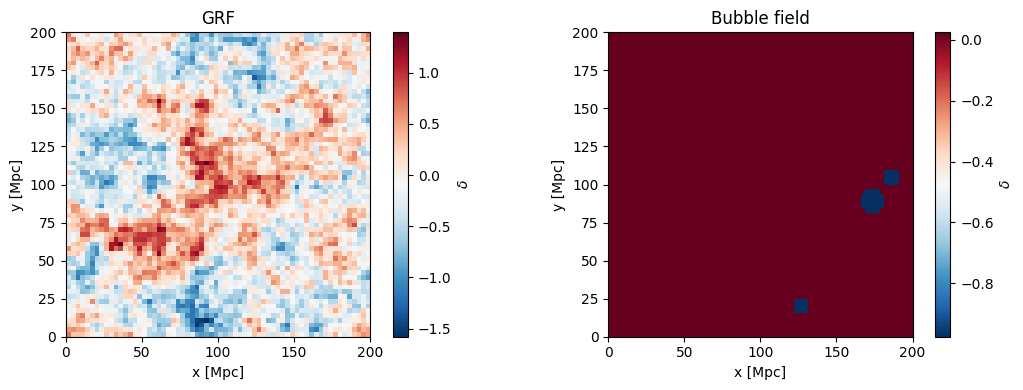

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, d, title in zip(axes, [d_grf, d_bubble], ['GRF', 'Bubble field']):
    im = ax.imshow(d[:, :, N // 2], origin='lower',
                   extent=[0, box_Mpc, 0, box_Mpc], cmap='RdBu_r')
    plt.colorbar(im, ax=ax, label=r'$\delta$')
    ax.set_title(title)
    ax.set_xlabel('x [Mpc]'); ax.set_ylabel('y [Mpc]')
plt.tight_layout(); plt.show()

## 2. Power spectrum: Polyspectrum ($n=2$) vs `power_spectrum_1d`

Setting `dk='auto'` makes each shell width equal the bin width, reproducing
the tophat binning used by `power_spectrum_1d` exactly.
Both estimators use the same explicit bin-edge array `kbins`; they should agree
to within $\lesssim 1\%$ on all bins.


In [4]:
# ── Shared logarithmic bin edges ─────────────────────────────────────────
n_kbins = 16
kbins   = np.geomspace(k_fundamental * 1.5, k_nyquist, n_kbins + 1)
k_cen   = np.sqrt(kbins[:-1] * kbins[1:])          # geometric bin centres

# ── Reference: standard 1D power spectrum ────────────────────────────────
Pk_grf,    _ = t2c.power_spectrum_1d(d_grf,    kbins=kbins, box_dims=box_Mpc)
Pk_bubble, _ = t2c.power_spectrum_1d(d_bubble, kbins=kbins, box_dims=box_Mpc)

# ── Polyspectrum n=2 (same kbins passed as explicit edges, dk='auto') ────
ps2_grf    = Polyspectrum(d_grf,    box_dims=box_Mpc, verbose=False)
ps2_bubble = Polyspectrum(d_bubble, box_dims=box_Mpc, verbose=False)

res2_grf    = ps2_grf.polyspectrum_equilateral(
    n_point=2, dk='auto', n_bins=kbins, verbose=False)
res2_bubble = ps2_bubble.polyspectrum_equilateral(
    n_point=2, dk='auto', n_bins=kbins, verbose=False)

print('Polyspectrum n=2 vs power_spectrum_1d:')
print(f'  GRF    max |rel error|: {np.nanmax(np.abs(res2_grf["P"]    / Pk_grf    - 1)):.2e}')
print(f'  Bubble max |rel error|: {np.nanmax(np.abs(res2_bubble["P"] / Pk_bubble - 1)):.2e}')

100%|██████████| 16/16 [00:00<00:00, 34.24it/s]

Polyspectrum n=2 vs power_spectrum_1d:
  GRF    max |rel error|: 7.62e-03
  Bubble max |rel error|: 4.26e-03


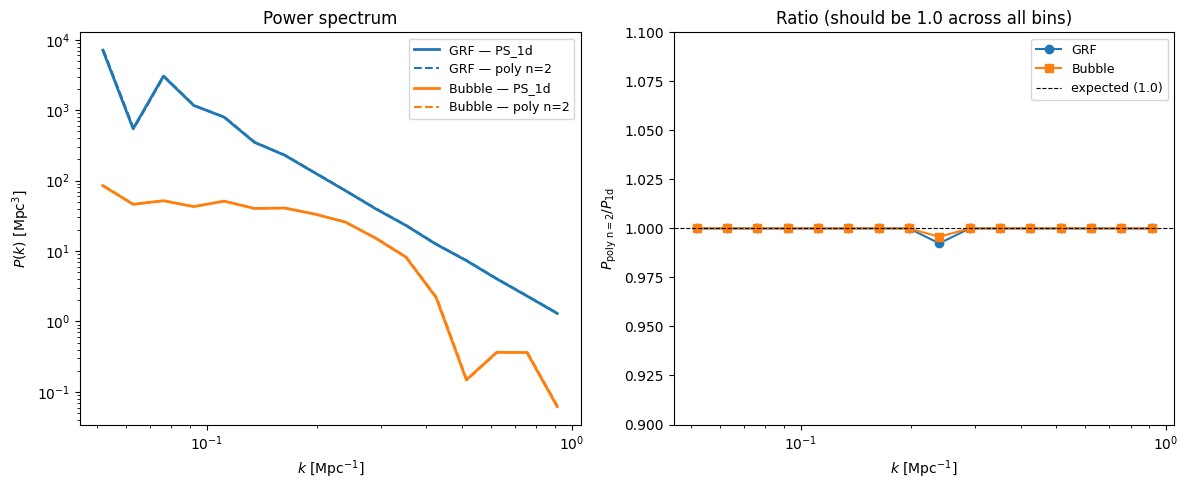

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ── Left: absolute P(k) ───────────────────────────────────────────────────
ax = axes[0]
ax.loglog(k_cen,            Pk_grf,            'C0-',  lw=2,   label='GRF — PS_1d')
ax.loglog(res2_grf['k'],    res2_grf['P'],     'C0--', lw=1.5, label='GRF — poly n=2')
ax.loglog(k_cen,            Pk_bubble,         'C1-',  lw=2,   label='Bubble — PS_1d')
ax.loglog(res2_bubble['k'], res2_bubble['P'],  'C1--', lw=1.5, label='Bubble — poly n=2')
ax.set_xlabel(r'$k$ [Mpc$^{-1}$]')
ax.set_ylabel(r'$P(k)$ [Mpc$^3$]')
ax.set_title('Power spectrum')
ax.legend(fontsize=9)

# ── Right: ratio ─────────────────────────────────────────────────────────
ax = axes[1]
ax.semilogx(k_cen, res2_grf['P']    / Pk_grf,    'C0o-', lw=1.5, ms=6, label='GRF')
ax.semilogx(k_cen, res2_bubble['P'] / Pk_bubble, 'C1s-', lw=1.5, ms=6, label='Bubble')
ax.axhline(1, c='k', ls='--', lw=0.8, label='expected (1.0)')
ax.set_ylim(0.9, 1.1)
ax.set_xlabel(r'$k$ [Mpc$^{-1}$]')
ax.set_ylabel(r'$P_{\rm poly\ n=2} / P_{\rm 1d}$')
ax.set_title('Ratio (should be 1.0 across all bins)')
ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

## 3. Equilateral bispectrum $B(k,k,k)$

`Bispectrum.bispectrum_k` delegates to `Polyspectrum.polyspectrum_equilateral(n_point=3)`.
For a Gaussian field $B\approx 0$ (residual noise from cosmic variance); for the bubble field $B>0$.

The kmax for $n\geq 3$ is $k_{\rm max}^{\rm grid}/2$ to ensure triangles can close on the grid.


In [6]:
n_bins_bs = 8
dk_bs     = 0.3    # Mpc^-1 (fixed shell width)

bs_grf    = Bispectrum(d_grf,    box_dims=box_Mpc, verbose=False)
bs_bubble = Bispectrum(d_bubble, box_dims=box_Mpc, verbose=False)

res_bs_grf    = bs_grf.bispectrum_k(   dk=dk_bs, n_bins=n_bins_bs, binning='log', verbose=True)
res_bs_bubble = bs_bubble.bispectrum_k(dk=dk_bs, n_bins=n_bins_bs, binning='log', verbose=True)

Computing equilateral 3-point polyspectrum...
FFT done


100%|██████████| 8/8 [00:00<00:00, 30.72it/s]


...done | Runtime: 0.271 s
Computing equilateral 3-point polyspectrum...
FFT done


100%|██████████| 8/8 [00:00<00:00, 33.04it/s]

...done | Runtime: 0.254 s


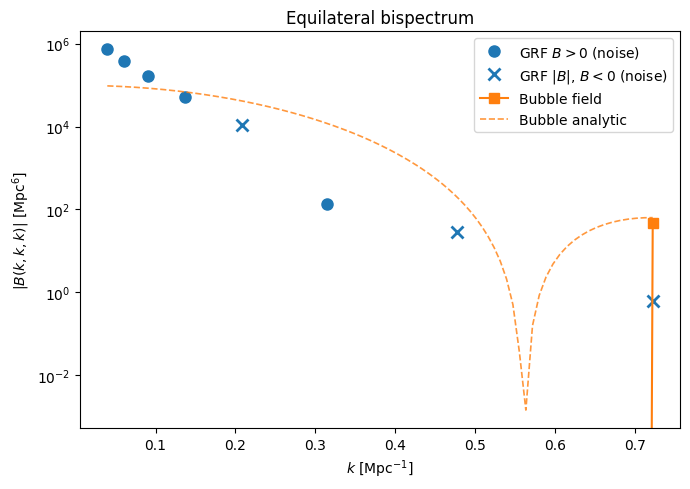

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))

k_g = res_bs_grf['k'];    B_g = res_bs_grf['B']
k_b = res_bs_bubble['k']; B_b = res_bs_bubble['B']

# GRF: show sign of noise separately (cosmic variance can flip sign)
pos_g = B_g >= 0;  neg_g = ~pos_g
if pos_g.any():
    ax.semilogy(k_g[pos_g],  B_g[pos_g],  'C0o', ms=8, label='GRF $B>0$ (noise)')
if neg_g.any():
    ax.semilogy(k_g[neg_g], -B_g[neg_g],  'C0x', ms=8, mew=2, label='GRF $|B|$, $B<0$ (noise)')
ax.semilogy(k_b, B_b, 'C1s-', lw=1.5, ms=7, label='Bubble field')
k_eq_plot = np.geomspace(k_b.min(), k_b.max(), 200)
ax.semilogy(k_eq_plot, np.abs(B_bubble_eq(k_eq_plot)),
            'C1--', lw=1.2, alpha=0.8, label='Bubble analytic')


ax.set_xlabel(r'$k$ [Mpc$^{-1}$]')
ax.set_ylabel(r'$|B(k,k,k)|$ [Mpc$^6$]')
ax.set_title('Equilateral bispectrum')
ax.legend()
plt.tight_layout(); plt.show()

### 3.1 Comparison with Pylians

For an equilateral triangle $k_1=k_2=k_3=k$ the opening angle between
$\mathbf{k}_1$ and $\mathbf{k}_2$ is $\theta=2\pi/3$ (120°), since
$k^2 = 2k^2 + 2k^2\cos\theta \Rightarrow \cos\theta = -\tfrac{1}{2}$.
We call `BispectrumPylians.bispectrum_k1k2(k, k, n_bins=np.array([2π/3]))` for each bin.



Computing bispectrum of the field...
Time to compute bispectrum = 0.05

Computing bispectrum of the field...
Time to compute bispectrum = 0.02

Computing bispectrum of the field...
Time to compute bispectrum = 0.23

Computing bispectrum of the field...
Time to compute bispectrum = 0.03

Computing bispectrum of the field...
Time to compute bispectrum = 0.06

Computing bispectrum of the field...
Time to compute bispectrum = 0.02

Computing bispectrum of the field...
Time to compute bispectrum = 0.03

Computing bispectrum of the field...
Time to compute bispectrum = 0.03

Computing bispectrum of the field...
Time to compute bispectrum = 0.03

Computing bispectrum of the field...
Time to compute bispectrum = 0.03

Computing bispectrum of the field...
Time to compute bispectrum = 0.02

Computing bispectrum of the field...
Time to compute bispectrum = 0.04

Computing bispectrum of the field...
Time to compute bispectrum = 0.21

Computing bispectrum of the field...
Time to compute bispectrum

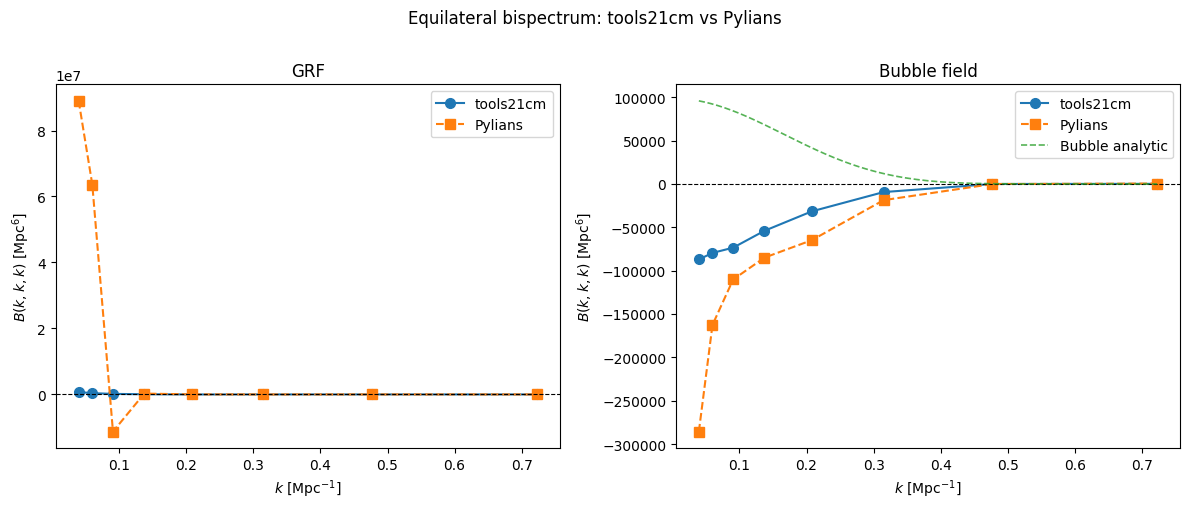

In [8]:
if _pylians:
    theta_eq = np.array([2 * np.pi / 3])   # equilateral condition

    bsp_grf    = BispectrumPylians(d_grf,    box_dims=box_Mpc, verbose=False, n_jobs=1)
    bsp_bubble = BispectrumPylians(d_bubble, box_dims=box_Mpc, verbose=False, n_jobs=1)

    Bk_pyl_grf    = np.array([bsp_grf.bispectrum_k1k2(   k, k, n_bins=theta_eq)['Bk'][0]
                               for k in res_bs_grf['k']])
    Bk_pyl_bubble = np.array([bsp_bubble.bispectrum_k1k2(k, k, n_bins=theta_eq)['Bk'][0]
                               for k in res_bs_bubble['k']])

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, B_t21, k_t21, B_pyl, label in zip(
        axes,
        [res_bs_grf['B'],    res_bs_bubble['B']],
        [res_bs_grf['k'],    res_bs_bubble['k']],
        [Bk_pyl_grf,         Bk_pyl_bubble],
        ['GRF', 'Bubble field'],
    ):
        ax.plot(k_t21, B_t21, 'C0o-',  lw=1.5, ms=7, label='tools21cm')
        ax.plot(k_t21, B_pyl, 'C1s--', lw=1.5, ms=7, label='Pylians')
        ax.axhline(0, c='k', ls='--', lw=0.8)
        ax.set_xlabel(r'$k$ [Mpc$^{-1}$]')
        ax.set_ylabel(r'$B(k,k,k)$ [Mpc$^6$]')
        ax.set_title(label)
        ax.legend()
    # Add analytic curve to the bubble (second) panel
    _kp = np.geomspace(res_bs_bubble['k'].min(), res_bs_bubble['k'].max(), 200)
    axes[1].plot(_kp, B_bubble_eq(_kp), 'C2--', lw=1.2, alpha=0.8, label='Bubble analytic')
    axes[1].legend()
    plt.suptitle('Equilateral bispectrum: tools21cm vs Pylians', y=1.01)
    plt.tight_layout(); plt.show()
else:
    print('Pylians3 not available — skipping comparison.')

## 4. Isosceles bispectrum $B(k_1, k_1, k_3)$

Fix $k_1=k_2$ and scan the opening angle $\alpha\in[0,\pi]$.
The third side follows from the triangle closure:
$k_3 = \sqrt{2k_1^2(1+\cos\alpha)}$.

| $\alpha$ | Triangle type |
|---|---|
| $0$ | elongated ($k_3 = 2k_1$) |
| $2\pi/3$ | equilateral ($k_3 = k_1$) |
| $\pi$ | squeezed / folded ($k_3 \to 0$) |

`alpha` (tools21cm) = `theta` (Pylians): both use the angle between $\mathbf{k}_1$ and $\mathbf{k}_2$.


100%|██████████| 15/15 [00:00<00:00, 15.78it/s]


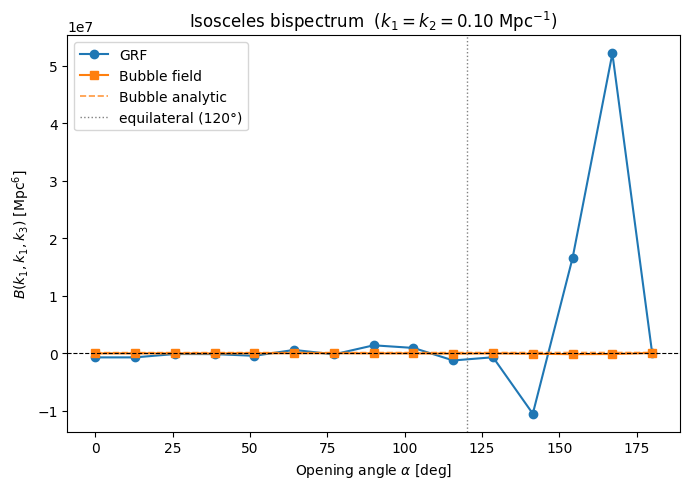

In [9]:
k_iso  = 0.10   # fixed k1 = k2 [Mpc^-1]
dk_iso = 0.03   # shell width [Mpc^-1]
n_ang  = 15

res_iso_grf    = bs_grf.bispectrum_k1k2(
    k_iso, k_iso, dk=dk_iso, n_bins=n_ang, binning='linear', verbose=False)
res_iso_bubble = bs_bubble.bispectrum_k1k2(
    k_iso, k_iso, dk=dk_iso, n_bins=n_ang, binning='linear', verbose=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(np.degrees(res_iso_grf['alpha']),    res_iso_grf['B'],    'C0o-', lw=1.5, label='GRF')
ax.plot(np.degrees(res_iso_bubble['alpha']), res_iso_bubble['B'], 'C1s-', lw=1.5, label='Bubble field')

# Analytic isosceles for bubble field
_alpha_plot = np.linspace(0, np.pi, 300)
_k3_plot    = np.sqrt(2 * k_iso**2 * (1 + np.cos(_alpha_plot)))
ax.plot(np.degrees(_alpha_plot), B_bubble_iso(k_iso, _k3_plot),
        'C1--', lw=1.2, alpha=0.8, label='Bubble analytic')
ax.axhline(0, c='k', ls='--', lw=0.8)
ax.axvline(120, c='grey', ls=':', lw=1, label='equilateral (120°)')
ax.set_xlabel(r'Opening angle $\alpha$ [deg]')
ax.set_ylabel(r'$B(k_1, k_1, k_3)$ [Mpc$^6$]')
ax.set_title(f'Isosceles bispectrum  ($k_1=k_2={k_iso:.2f}$ Mpc$^{{-1}}$)')
ax.legend()
plt.tight_layout(); plt.show()

### 4.1 Comparison with Pylians

Both codes use the same convention: the scan parameter is the angle
$\alpha$ between $\mathbf{k}_1$ and $\mathbf{k}_2$ running from 0 (elongated) to $\pi$ (squeezed).



Computing bispectrum of the field...
Time to compute bispectrum = 0.32

Computing bispectrum of the field...
Time to compute bispectrum = 0.37


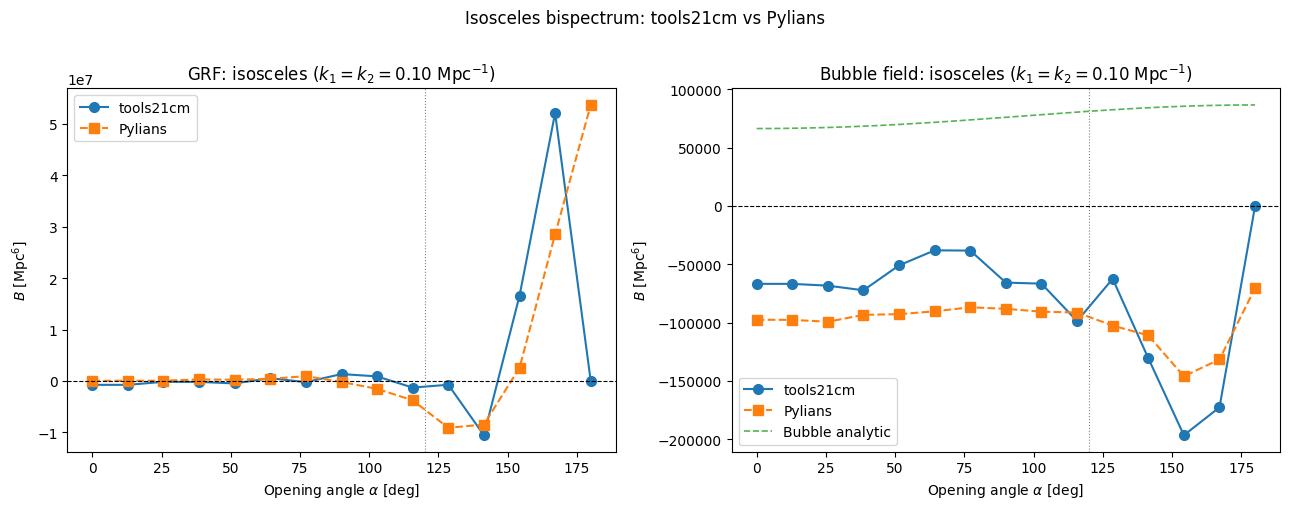

In [10]:
if _pylians:
    bsp_grf_iso    = BispectrumPylians(d_grf,    box_dims=box_Mpc, verbose=False, n_jobs=1)
    bsp_bubble_iso = BispectrumPylians(d_bubble, box_dims=box_Mpc, verbose=False, n_jobs=1)

    res_pyl_grf    = bsp_grf_iso.bispectrum_k1k2(k_iso, k_iso, n_bins=n_ang)
    res_pyl_bubble = bsp_bubble_iso.bispectrum_k1k2(k_iso, k_iso, n_bins=n_ang)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    triples = [
        (res_iso_grf,    res_pyl_grf,    'GRF'),
        (res_iso_bubble, res_pyl_bubble, 'Bubble field'),
    ]
    for ax, (res_t21, res_pyl, label) in zip(axes, triples):
        ax.plot(np.degrees(res_t21['alpha']), res_t21['B'],  'C0o-',  lw=1.5, ms=7, label='tools21cm')
        ax.plot(np.degrees(res_pyl['theta']), res_pyl['Bk'], 'C1s--', lw=1.5, ms=7, label='Pylians')
        ax.axhline(0, c='k', ls='--', lw=0.8)
        ax.axvline(120, c='grey', ls=':', lw=0.8)
        ax.set_xlabel(r'Opening angle $\alpha$ [deg]')
        ax.set_ylabel(r'$B$ [Mpc$^6$]')
        ax.set_title(f'{label}: isosceles $(k_1=k_2={k_iso:.2f}$ Mpc$^{{-1}})$')
        ax.legend()
    # Add analytic curve to the bubble (second) panel
    _aa = np.linspace(0, np.pi, 300)
    _k3 = np.sqrt(2 * k_iso**2 * (1 + np.cos(_aa)))
    axes[1].plot(np.degrees(_aa), B_bubble_iso(k_iso, _k3),
                 'C2--', lw=1.2, alpha=0.8, label='Bubble analytic')
    axes[1].legend()
    plt.suptitle('Isosceles bispectrum: tools21cm vs Pylians', y=1.01)
    plt.tight_layout(); plt.show()
else:
    print('Pylians3 not available — skipping comparison.')

## 5. Reduced bispectrum $Q_{\rm eq}$

$$Q_{\rm eq}(k) = \frac{B(k,k,k)}{3\,P(k)^2}$$

Dividing by $P^2$ removes the overall power-spectrum normalisation.
For a Gaussian field $Q_{\rm eq}\approx 0$; for Poisson spheres $Q_{\rm eq}>0$ and
grows toward the squeezed limit (Bharadwaj & Pandey 2005).


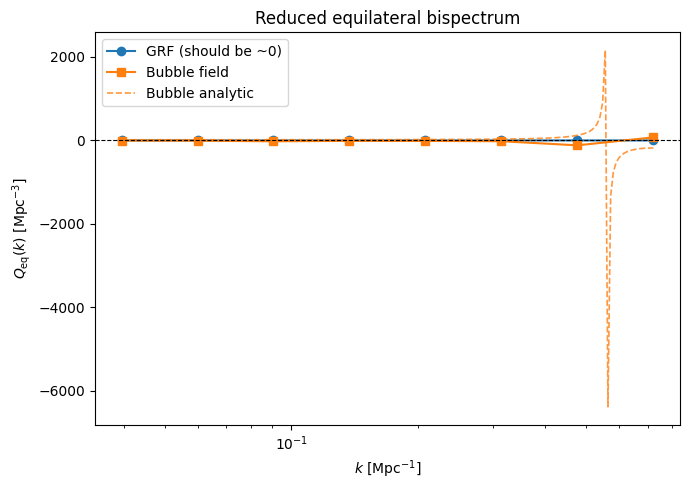

In [11]:
# Dense PS for interpolating P(k) at the bispectrum k-centres
Pk_dense_grf,    k_dense = t2c.power_spectrum_1d(d_grf,    kbins=50, box_dims=box_Mpc)
Pk_dense_bubble, _       = t2c.power_spectrum_1d(d_bubble, kbins=50, box_dims=box_Mpc)

Pk_grf_at_bs    = np.interp(res_bs_grf['k'],    k_dense, Pk_dense_grf)
Pk_bubble_at_bs = np.interp(res_bs_bubble['k'], k_dense, Pk_dense_bubble)

Q_grf    = res_bs_grf['B']    / (3 * Pk_grf_at_bs**2)
Q_bubble = res_bs_bubble['B'] / (3 * Pk_bubble_at_bs**2)

fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogx(res_bs_grf['k'],    Q_grf,    'C0o-', lw=1.5, label='GRF (should be ~0)')
ax.semilogx(res_bs_bubble['k'], Q_bubble, 'C1s-', lw=1.5, label='Bubble field')

# Analytic Q for bubble field
_k_q = np.geomspace(res_bs_bubble['k'].min(), res_bs_bubble['k'].max(), 200)
_Q_analytic = Q_bubble_analytic(_k_q)
ax.semilogx(_k_q, _Q_analytic, 'C1--', lw=1.2, alpha=0.8, label='Bubble analytic')
ax.axhline(0, c='k', ls='--', lw=0.8)
ax.set_xlabel(r'$k$ [Mpc$^{-1}$]')
ax.set_ylabel(r'$Q_{\rm eq}(k)$ [Mpc$^{-3}$]')
ax.set_title('Reduced equilateral bispectrum')
ax.legend()
plt.tight_layout(); plt.show()